# Dataset context and model behavior

This notebook gives a compact overview of the processed PURE requirements dataset and the behavior of the fine-tuned RoBERTa ambiguity detector on its held-out, source-disjoint test set. It combines the contextual analyses needed to interpret the model with the behavioral slices that motivate the separate multiple-actions investigation.

## Questions addressed

1. What data and test split are being analyzed?
2. Which selected linguistic cues are more prevalent in ambiguous versus unambiguous requirements?
3. What kinds of held-out errors does the model make?
4. Does the model's reported confidence align with observed correctness?
5. Does requirement length change false-positive or false-negative rates?
6. Which human-annotated reasons and source documents are associated with more model errors?

## Load data and run artefacts

The loader searches upward from the notebook's working directory, so it works when launched from the repository root or from `phase1/AI-aided`. It accepts both the current `data/pure_clean.csv` layout and the earlier `data/processed/pure_clean.csv` layout.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "axes.titleweight": "bold"})

PROJECT_ROOT = None  # Set to Path(r".../jku_ai-vis_mighty-pythons") only if discovery fails.

def find_project_root():
    if PROJECT_ROOT is not None:
        return Path(PROJECT_ROOT)
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    for candidate in candidates:
        has_data = any((candidate / relative).exists() for relative in (
            Path("data/pure_clean.csv"), Path("data/processed/pure_clean.csv")
        ))
        if has_data and (candidate / "results/roberta-pure-seed42/test_predictions.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Set PROJECT_ROOT to the repository directory."
    )

ROOT = find_project_root()
data_path = next(
    ROOT / relative for relative in (Path("data/pure_clean.csv"), Path("data/processed/pure_clean.csv"))
    if (ROOT / relative).exists()
)
results_dir = ROOT / "results" / "roberta-pure-seed42"
pred_path = results_dir / "test_predictions.csv"
metrics_path = results_dir / "test_metrics.json"
metadata_path = results_dir / "run_metadata.json"

pure = pd.read_csv(data_path)
pred = pd.read_csv(pred_path)
metrics = json.loads(metrics_path.read_text(encoding="utf-8")) if metrics_path.exists() else {}
metadata = json.loads(metadata_path.read_text(encoding="utf-8")) if metadata_path.exists() else {}

for frame, name, columns in [
    (pure, "processed dataset", {"requirement_text", "label", "reasons"}),
    (pred, "test predictions", {"instance_id", "requirement_text", "true_label", "predicted_label", "probability_ambiguous", "reasons"}),
]:
    missing = columns - set(frame.columns)
    if missing:
        raise ValueError(f"The {name} file is missing columns: {sorted(missing)}")

pure["requirement_text"] = pure["requirement_text"].fillna("").astype(str)
pure["label"] = pd.to_numeric(pure["label"], errors="raise").astype(int)
pure["reasons"] = pure["reasons"].fillna("").astype(str)
pred["requirement_text"] = pred["requirement_text"].fillna("").astype(str)
pred["true_label"] = pd.to_numeric(pred["true_label"], errors="raise").astype(int)
pred["predicted_label"] = pd.to_numeric(pred["predicted_label"], errors="raise").astype(int)
pred["probability_ambiguous"] = pd.to_numeric(pred["probability_ambiguous"], errors="coerce")
pred["correct"] = pred["true_label"].eq(pred["predicted_label"])
pred["confidence"] = np.where(pred["predicted_label"].eq(1), pred["probability_ambiguous"], 1 - pred["probability_ambiguous"])
pred["word_count"] = pred["requirement_text"].str.split().str.len()
pred["error_type"] = np.select(
    [(pred.true_label.eq(0) & pred.predicted_label.eq(1)), (pred.true_label.eq(1) & pred.predicted_label.eq(0))],
    ["False positive", "False negative"], default="Correct"
)

print(f"Project root: {ROOT}")
print(f"Dataset: {data_path.relative_to(ROOT)} ({len(pure):,} rows)")
print(f"Test predictions: {pred_path.relative_to(ROOT)} ({len(pred):,} rows)")

Project root: C:\Users\vprot\Documents\Masters_AI\3_semester\jku_ai-vis_mighty-pythons
Dataset: data\pure_clean.csv (6,534 rows)
Test predictions: results\roberta-pure-seed42\test_predictions.csv (1,308 rows)


### Model setup

The saved run fine-tunes `FacebookAI/roberta-base` for three epochs (seed 42; maximum sequence length 256) and uses a 0.50 ambiguity threshold. The checkpoint was selected by validation macro-F1; the figures below evaluate the saved model only on the held-out source-disjoint test split.

## 1. What data and test split are being analyzed?

The table distinguishes the full processed dataset from the held-out test split. The test split is source-disjoint: its documents were not used for training or validation. This is contextual information, not a performance result.

In [2]:
split_summary = metadata.get("split_summary", {})
dataset_context = pd.DataFrame([
    {
        "Subset": "Processed PURE dataset",
        "Requirements": len(pure),
        "Ambiguous": int(pure.label.eq(1).sum()),
        "Unambiguous": int(pure.label.eq(0).sum()),
        "Sources": pure["source_file"].nunique() if "source_file" in pure else np.nan,
    },
    {
        "Subset": "Held-out test split",
        "Requirements": len(pred),
        "Ambiguous": int(pred.true_label.eq(1).sum()),
        "Unambiguous": int(pred.true_label.eq(0).sum()),
        "Sources": split_summary.get("test", {}).get("sources", pred["source_file"].nunique() if "source_file" in pred else np.nan),
    },
])
dataset_context["Ambiguous share (%)"] = (100 * dataset_context["Ambiguous"] / dataset_context["Requirements"]).round(1)
display(dataset_context)

config = metadata.get("config", {})
print(
    f"Model: {config.get('model_name', 'not recorded')} | "
    f"threshold: {config.get('threshold', metrics.get('threshold', 'not recorded'))} | "
    f"selected by: {metadata.get('selection_metric', 'not recorded')}"
)

,Subset,Requirements,Ambiguous,Unambiguous,Sources,Ambiguous share (%)
0,Processed PURE dataset,6534,3331,3203,66,51.0
1,Held-out test split,1308,667,641,14,51.0


Model: FacebookAI/roberta-base | threshold: 0.5 | selected by: validation macro-F1


**Answer.** The analysis uses 6,534 processed PURE requirements and a held-out test set of 1,308 requirements from 14 source documents. Every model-behaviour result below refers to that test set.

## 2. Which selected linguistic cues are more prevalent in ambiguous versus unambiguous requirements?

Each bar is the share of requirements in that label class containing the cue at least once. These are deliberately simple lexical indicators, not ambiguity rules: wording can be unproblematic in context, and the patterns do not capture all paraphrases.

Label,Unambiguous,Ambiguous
Cue,,
Passive-form cue,28.5,35.6
Pronouns,26.4,38.3
Quantifiers,13.3,19.1
Vague terms,0.2,5.0
must,17.8,11.1
shall,60.6,25.0
should,0.0,32.7


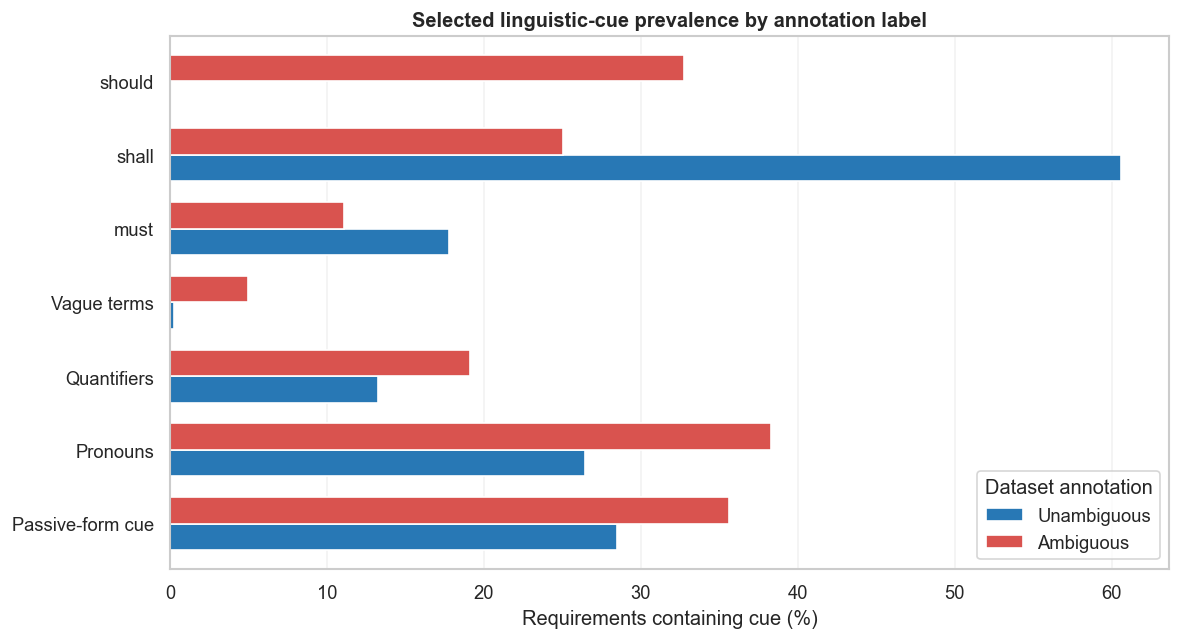

In [3]:
cue_patterns = {
    "Pronouns": r"\b(?:it|they|them|their|this|that|these|those|he|she|we|you)\b",
    "Vague terms": r"\b(?:appropriate|adequate|reasonable|user-friendly|efficient|quickly|easy|robust|flexible)\b",
    "Quantifiers": r"\b(?:some|many|few|several|most|all|any|multiple|various)\b",
    "should": r"\bshould\b",
    "shall": r"\bshall\b",
    "must": r"\bmust\b",
    "Passive-form cue": r"\b(?:is|are|was|were|be|been|being)\s+\w+(?:ed|en)\b",
}
label_names = {0: "Unambiguous", 1: "Ambiguous"}
cue_rows = []
texts = pure.requirement_text.str.lower()
for cue, pattern in cue_patterns.items():
    present = texts.str.contains(pattern, regex=True, na=False)
    for label in [0, 1]:
        in_class = pure.label.eq(label)
        cue_rows.append({"Cue": cue, "Label": label_names[label], "Prevalence (%)": 100 * present[in_class].mean()})
cue_pivot = pd.DataFrame(cue_rows).pivot(index="Cue", columns="Label", values="Prevalence (%)").reindex(columns=["Unambiguous", "Ambiguous"])
display(cue_pivot.round(1))

ax = cue_pivot.plot.barh(figsize=(10, 5.5), color={"Unambiguous": "#2878B5", "Ambiguous": "#D9534F"}, width=.72)
ax.set(title="Selected linguistic-cue prevalence by annotation label", xlabel="Requirements containing cue (%)", ylabel="")
ax.legend(title="Dataset annotation", loc="lower right")
ax.grid(axis="x", alpha=.25); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Answer.** `should` has the largest prevalence difference: it occurs in 32.7% of ambiguous requirements and none of the unambiguous requirements. `shall` shows the opposite pattern (25.0% versus 60.6%). These are dataset associations, not decision rules.

## 3. What kinds of held-out errors does the model make?

The off-diagonal cells are the errors: false positives send unambiguous requirements for unnecessary review, while false negatives miss annotated ambiguity. The percentages are shares of this specific held-out test set.

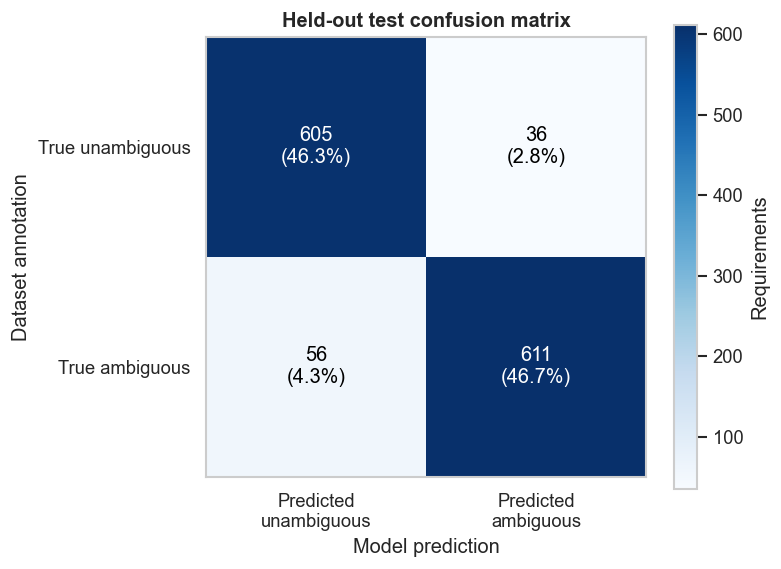

Accuracy: 93.0% | false positives: 36 (5.6% of true unambiguous) | false negatives: 56 (8.4% of true ambiguous)


In [4]:
cm = confusion_matrix(pred.true_label, pred.predicted_label, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(6.5, 5.1))
image = ax.imshow(cm, cmap="Blues")
ax.set(xticks=[0, 1], xticklabels=["Predicted\nunambiguous", "Predicted\nambiguous"], yticks=[0, 1], yticklabels=["True unambiguous", "True ambiguous"], xlabel="Model prediction", ylabel="Dataset annotation", title="Held-out test confusion matrix")
for row in range(2):
    for col in range(2):
        value = cm[row, col]
        ax.text(col, row, f"{value:,}\n({value / cm.sum():.1%})", ha="center", va="center", fontsize=12, color="white" if value > cm.max() / 2 else "black")
fig.colorbar(image, ax=ax, label="Requirements")
ax.grid(False)
plt.tight_layout(); plt.show()

print(f"Accuracy: {pred.correct.mean():.1%} | false positives: {fp:,} ({fp / (tn + fp):.1%} of true unambiguous) | false negatives: {fn:,} ({fn / (fn + tp):.1%} of true ambiguous)")

**Answer.** The detector makes more false negatives than false positives: 56 ambiguous requirements are missed (8.4% of true ambiguous requirements), while 36 unambiguous requirements are flagged (5.6% of true unambiguous requirements).

## 4. Does the model's reported confidence align with observed correctness?

Each point compares mean confidence with observed accuracy within a confidence bin; point labels give bin sample sizes. Points below the dashed diagonal indicate overconfidence. This checks confidence in the predicted class, rather than calibration of the ambiguous-class probability alone.

,bin,n,mean_confidence,observed_accuracy
0,"(0.5, 0.6]",7,0.539202,0.714286
1,"(0.6, 0.7]",14,0.650025,0.571429
2,"(0.7, 0.8]",10,0.758934,0.700000
3,"(0.8, 0.9]",22,0.855028,0.500000
4,"(0.9, 1.0]",1255,0.993098,0.944223


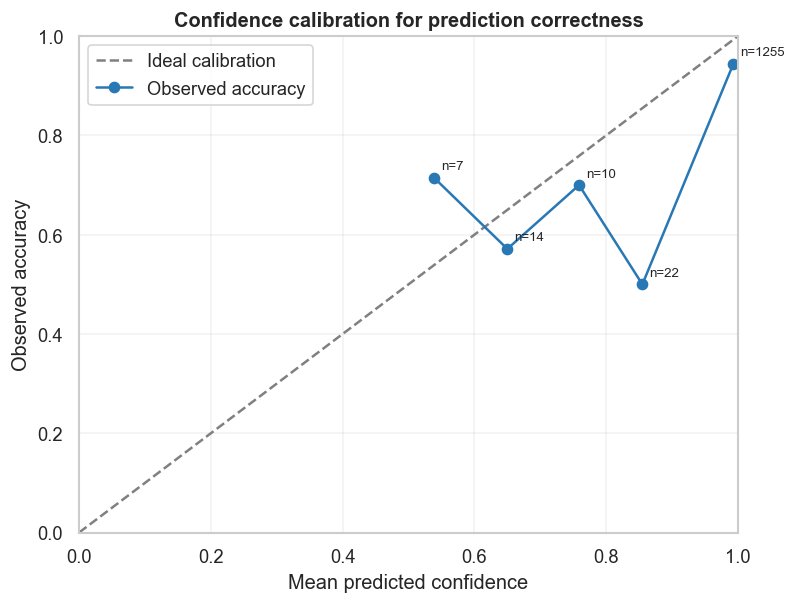

10-bin ECE: 0.055 | errors with confidence ≥ 0.90: 70 of 92


In [5]:
cal = pred[["confidence", "correct"]].dropna().copy()
observed_accuracy, mean_confidence = calibration_curve(cal.correct.astype(int), cal.confidence, n_bins=10, strategy="uniform")
cal["bin"] = pd.cut(cal.confidence, bins=np.linspace(0, 1, 11), include_lowest=True)
calibration_table = (cal.groupby("bin", observed=False).agg(n=("correct", "size"), mean_confidence=("confidence", "mean"), observed_accuracy=("correct", "mean")).dropna().reset_index())
display(calibration_table)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Ideal calibration")
ax.plot(mean_confidence, observed_accuracy, marker="o", color="#2878B5", label="Observed accuracy")
for row in calibration_table.itertuples():
    ax.annotate(f"n={row.n}", (row.mean_confidence, row.observed_accuracy), xytext=(4, 5), textcoords="offset points", fontsize=8)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted confidence", ylabel="Observed accuracy", title="Confidence calibration for prediction correctness")
ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

ece = (calibration_table.apply(lambda row: row.n * abs(row.mean_confidence - row.observed_accuracy), axis=1).sum() / len(cal))
confident_errors = ((~pred.correct) & pred.confidence.ge(.9)).sum()
print(f"10-bin ECE: {ece:.3f} | errors with confidence ≥ 0.90: {confident_errors:,} of {(~pred.correct).sum():,}")

**Answer.** The 10-bin expected calibration error is 0.055. The largest observed gap is overconfidence in a bin with mean confidence 0.86 but observed accuracy 0.50 (n=22), and 70 of the 92 errors have confidence of at least 0.90.

## 5. Does requirement length change false-positive or false-negative rates?

Test requirements are grouped into word-count quartiles. Each rate uses the relevant true class as its denominator, so the chart separates over-flagging from missed ambiguity. Associations with length are descriptive: length may also stand in for source, topic, or sentence structure.

,Length band,Test requirements,False-positive rate,False-negative rate,True unambiguous (n),True ambiguous (n)
0,"(3.999, 15.0]",367,0.009950,0.066265,201,166
1,"(15.0, 20.0]",290,0.018519,0.093750,162,128
2,"(20.0, 28.0]",348,0.062500,0.095745,160,188
3,"(28.0, 213.0]",303,0.177966,0.081081,118,185


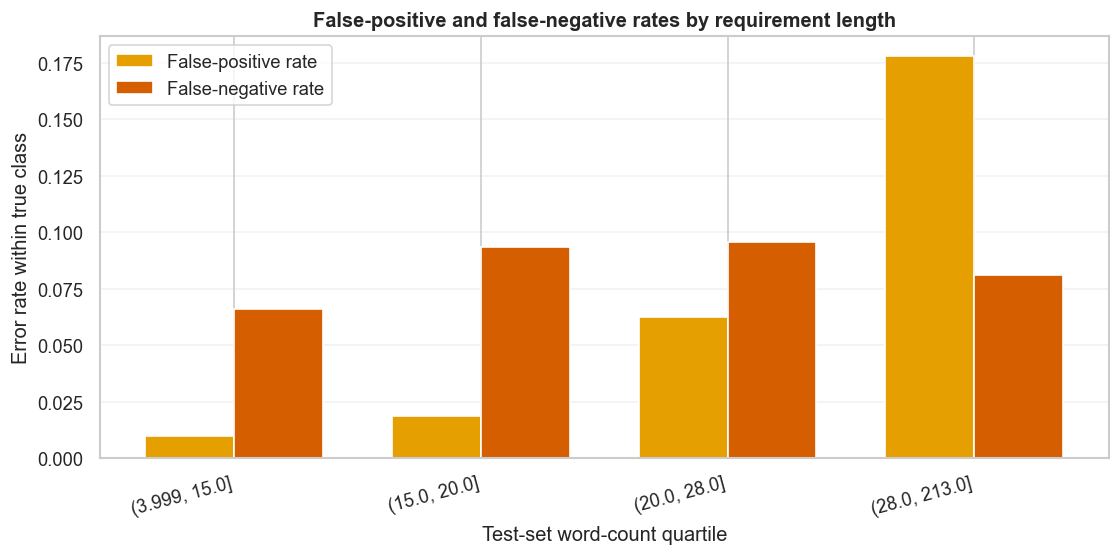

In [6]:
pred["length_band"] = pd.qcut(pred.word_count, q=4, duplicates="drop")
length_rows = []
for band, group in pred.groupby("length_band", observed=True):
    unambiguous = group[group.true_label.eq(0)]
    ambiguous = group[group.true_label.eq(1)]
    length_rows.append({
        "Length band": str(band), "Test requirements": len(group),
        "False-positive rate": unambiguous.predicted_label.eq(1).mean() if len(unambiguous) else np.nan,
        "False-negative rate": ambiguous.predicted_label.eq(0).mean() if len(ambiguous) else np.nan,
        "True unambiguous (n)": len(unambiguous), "True ambiguous (n)": len(ambiguous),
    })
length_summary = pd.DataFrame(length_rows)
display(length_summary)

x = np.arange(len(length_summary)); width = .36
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.bar(x - width / 2, length_summary["False-positive rate"], width, label="False-positive rate", color="#E69F00")
ax.bar(x + width / 2, length_summary["False-negative rate"], width, label="False-negative rate", color="#D55E00")
ax.set(xticks=x, xticklabels=length_summary["Length band"], xlabel="Test-set word-count quartile", ylabel="Error rate within true class", title="False-positive and false-negative rates by requirement length")
ax.legend(); ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

**Answer.** False negatives peak at 9.6% in the 20-28 word band, whereas false positives peak at 17.8% in the longest band (28-213 words). The displayed class-specific counts should be considered when comparing these rates.

## 6. Which human-annotated reasons are associated with more missed ambiguous requirements?

For each reason attached to a true ambiguous test requirement, the bar shows the share predicted as unambiguous. Labels include the number of annotated test requirements. Reasons overlap, so counts must not be added across bars; this is a slice analysis, not evidence that a reason causes a miss.

,reason,annotated_test_requirements,missed,miss_rate
0,multiple_actions,54,25,0.462963
1,missing_actor,56,7,0.125000
2,vague_term,293,22,0.075085
3,weak_modal,370,2,0.005405
4,undefined_quantity,32,0,0.000000
5,undefined_term,28,0,0.000000
6,vague_condition,6,0,0.000000


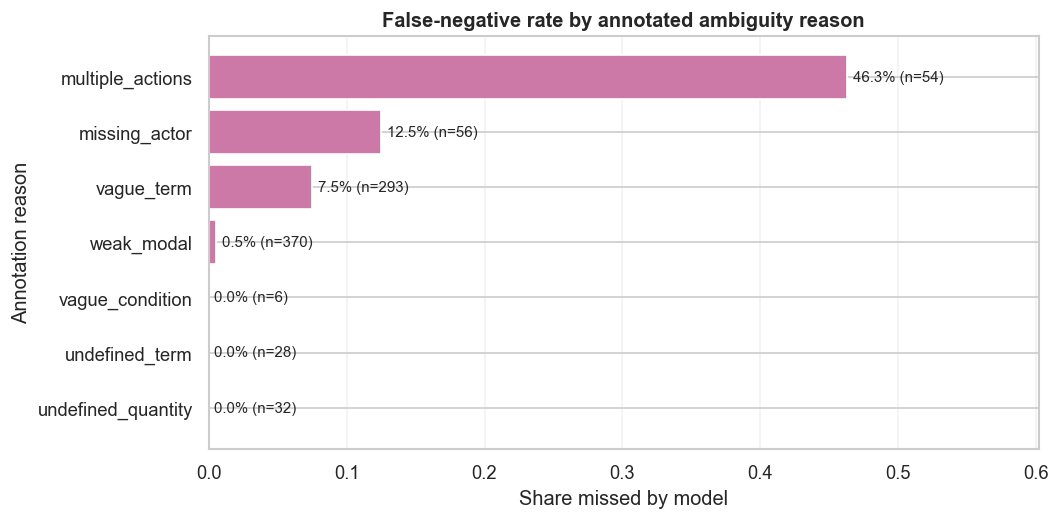

In [7]:
ambiguous_test = pred[pred.true_label.eq(1)].copy()
ambiguous_test["reason"] = ambiguous_test.reasons.fillna("").apply(lambda value: [item.strip() for item in str(value).split(",") if item.strip()])
reason_summary = (ambiguous_test.explode("reason").dropna(subset=["reason"]).query("reason != ''").groupby("reason").agg(
    annotated_test_requirements=("correct", "size"),
    missed=("predicted_label", lambda values: values.eq(0).sum()),
    miss_rate=("predicted_label", lambda values: values.eq(0).mean()),
).sort_values(["miss_rate", "annotated_test_requirements"], ascending=[False, False]).reset_index())
display(reason_summary)

plot_df = reason_summary.sort_values("miss_rate")
fig, ax = plt.subplots(figsize=(9, max(4.5, .55 * len(plot_df))))
ax.barh(plot_df.reason, plot_df.miss_rate, color="#CC79A7")
ax.set(xlabel="Share missed by model", ylabel="Annotation reason", title="False-negative rate by annotated ambiguity reason")
ax.set_xlim(0, max(.15, plot_df.miss_rate.max() * 1.3))
for y, row in enumerate(plot_df.itertuples()):
    ax.text(row.miss_rate + .004, y, f"{row.miss_rate:.1%} (n={row.annotated_test_requirements})", va="center", fontsize=9)
ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

**Answer.** `multiple_actions` has the highest observed miss rate: 46.3% (25 missed of 54 annotated test requirements). Since reasons overlap, this identifies the focused follow-up question rather than an isolated cause.

## 7. Are errors concentrated in particular source documents?

Only source documents with at least 20 test requirements are displayed to avoid visually amplifying tiny groups. A higher rate identifies a candidate for qualitative review, not proof of a document-specific model failure.

,source_file,test_requirements,errors,error_rate
0,2001 - esa.pdf,67,13,0.194030
1,2009 - warc III.pdf,42,6,0.142857
2,2010 - blit draft.pdf,61,8,0.131148
3,2010 - gparted.pdf,25,3,0.120000
4,2005 - pontis.pdf,250,25,0.100000
5,1998 - themas.pdf,106,9,0.084906
6,2001 - elsfork.pdf,122,10,0.081967
7,2004 - sprat.pdf,151,9,0.059603
8,2005 - phin.pdf,138,4,0.028986
9,2001 - ctc network.pdf,106,3,0.028302


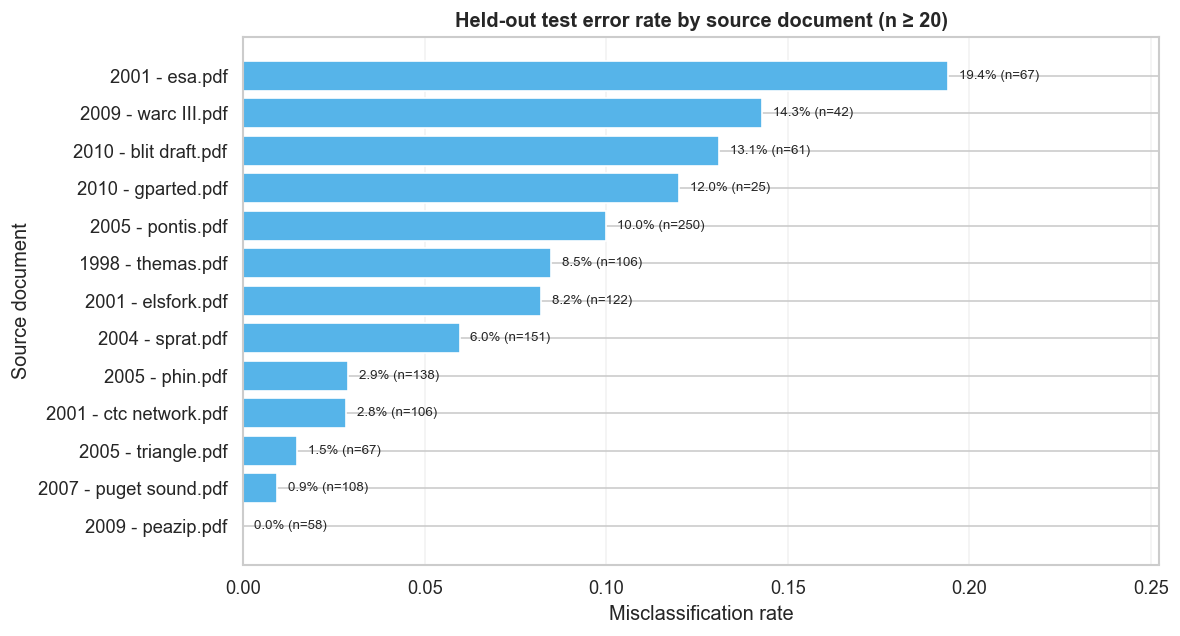

In [8]:
if "source_file" not in pred:
    print("Source-document identifiers are not available in the prediction artefact.")
else:
    source_summary = (pred.groupby("source_file").agg(
        test_requirements=("correct", "size"),
        errors=("correct", lambda values: (~values).sum()),
        error_rate=("correct", lambda values: 1 - values.mean()),
    ).query("test_requirements >= 20").sort_values("error_rate", ascending=False).reset_index())
    display(source_summary)
    plot_df = source_summary.sort_values("error_rate")
    fig, ax = plt.subplots(figsize=(10, max(4.5, .42 * len(plot_df))))
    ax.barh(plot_df.source_file, plot_df.error_rate, color="#56B4E9")
    ax.set(xlabel="Misclassification rate", ylabel="Source document", title="Held-out test error rate by source document (n ≥ 20)")
    ax.set_xlim(0, max(.15, plot_df.error_rate.max() * 1.3))
    for y, row in enumerate(plot_df.itertuples()):
        ax.text(row.error_rate + .003, y, f"{row.error_rate:.1%} (n={row.test_requirements})", va="center", fontsize=8)
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout(); plt.show()

**Answer.** Among documents with at least 20 test requirements, error rates range from 0.0% to 19.4%. `2001 - esa.pdf` has the highest rate (n=67), making it a candidate for qualitative review rather than evidence of a document-specific failure.

## 8. What do representative confident errors look like?

These two examples per error type are selected by confidence for qualitative inspection, not because they are statistically representative. A model error can also reflect limited context or annotation disagreement.

In [9]:
example_columns = [column for column in ["instance_id", "source_file", "requirement_text", "probability_ambiguous", "reasons"] if column in pred]
for error_type in ["False positive", "False negative"]:
    display(Markdown(f"### {error_type}s"))
    examples = pred[pred.error_type.eq(error_type)].sort_values("confidence", ascending=False)[example_columns].head(2).copy()
    display(examples)

### False positives

,instance_id,source_file,requirement_text,probability_ambiguous,reasons
708,PURE_003713,2005 - pontis.pdf,A web version of Pontis will offer easier appl...,0.999735,NaN
457,PURE_002878,2004 - sprat.pdf,The system will provide a way to display the d...,0.999702,NaN


### False negatives

,instance_id,source_file,requirement_text,probability_ambiguous,reasons
557,PURE_002978,2004 - sprat.pdf,The system shall generate an access log for ev...,0.005743,multiple_actions
678,PURE_003683,2005 - phin.pdf,2.5.10 Systems supporting OM must be able to c...,0.005939,multiple_actions
